# Контрольная точка 3.
# Задание 1
## Оценка и анализ гиперпараметров алгоритмов классификации

Задача: предсказание серьёзности последствий ДТП (US Accidents, ~7.7 млн строк). Целевая переменная бинаризована как `Severity >= 3` (переход к задаче бинарной классификации - "тяжёлое" ДТП против "нетяжёлого").

Метрики качества (выбраны с учётом несбалансированности классов):
- **ROC-AUC** - общая способность модели ранжировать объекты;
- **PR-AUC** - площадь под precision-recall кривой, устойчива к дисбалансу;
- **F1** - баланс precision/recall для миноритарного класса (с порогом 0.5);
- **Balanced Accuracy** - контроль того, что модель не "проваливается" в мажоритарный класс. Вычисляется как сумма чувствительности и специфичности, поделённая на 2.

Подбираемые модели (из списка методов КТ2): логистическая регрессия, дерево решений, KNN, случайный лес, XGBoost.

**Объём данных.** На полном наборе (~7.7M строк) перебор сетки гиперпараметров с кросс-валидацией нереализуем по времени, поэтому поиск выполняется на подвыборке с уменьшенным количеством строк. Логика такая: взаимное расположение моделей и общий вид оптимальных параметров от объёма выборки меняются слабо, а найденные значения потом переносятся на обучение по полным данным на последующих этапах.

Ещё одно условие из плана: в наборе есть пространственно-временные дубликаты - одна и та же авария, попавшая в несколько источников. В `analyze_sources.py` они объединены в группы (`group_id`: связные компоненты графа "Haversine <= 150 м и пересекаются по времени"), результат сохранён в `kt3/df_with_groups.csv.gz`. В этом ноутбуке группы используются для корректного разбиения выборки (см. ниже).

In [17]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             f1_score, balanced_accuracy_score)

warnings.filterwarnings("ignore")

# link_duplicates() - из kt3/analyze_sources.py (там же описание метода поиска повтором)
from analyze_sources import link_duplicates

DATA_PATH = r"C:\Users\musai\.cache\kagglehub\datasets\sobhanmoosavi\us-accidents\versions\13\US_Accidents_March23.csv"

NUM_COLS = ["Distance(mi)", "Temperature(F)", "Humidity(%)", "Pressure(in)",
            "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
BIN_COLS = ["Bump", "Crossing", "Junction", "Railway",
            "Station", "Stop", "Traffic_Signal", "Amenity"]

In [3]:
GROUPS_PATH = "df_with_groups.csv.gz"

try:
    # файл из analyze_sources.py: там уже посчитан group_id по полным данным
    df = pd.read_csv(GROUPS_PATH, low_memory=False)
    print(f"Загружен {GROUPS_PATH}: {len(df):,} строк, group_id уже есть")
except FileNotFoundError:
    df = pd.read_csv(DATA_PATH, low_memory=False)
    df["group_id"] = link_duplicates(df, radius_m=150.0, time_h=6.0)
    print("df_with_groups.csv.gz не найден - пересчитал group_id по short_file.csv")

for c in BIN_COLS:
    df[c] = df[c].astype("boolean").astype(float)   # True/False/NaN -> 1/0/NaN

df["y"] = (df["Severity"] >= 3).astype(int)

X = df[NUM_COLS + BIN_COLS]
y = df["y"]
gsize = df["group_id"].value_counts()
print(X.shape)
print(y.value_counts(normalize=True).round(4))
print(f"групп повтором: {len(gsize):,}, строк в группах size>1: {(gsize[gsize>1].sum()/len(df)):.2%}")

Загружен df_with_groups.csv.gz: 7,728,394 строк, group_id уже есть
(7728394, 15)
y
0    0.8054
1    0.1946
Name: proportion, dtype: float64
групп повтором: 6,773,248, строк в группах size>1: 20.30%


### Разбиение

- 20% - отложенная тестовая выборка (не участвует ни в подборе, ни в кроссвалидации);
- из оставшихся 80% берётся 15% (от общего объёма) для самого поиска по сетке;
- после выбора гиперпараметров модель переобучается на всём train и один раз оценивается на test.

Разбиение **по группам**, а не по строкам: все записи одной пространственно-временной группы уезжают либо в train, либо в test. Иначе копии одной аварии оказываются по разные стороны границы и тестовая метрика завышается\. Заодно это снимает перекос от того, что дубликаты несут одну и ту же метку несколько раз.

Для сравнения оставляю и обычный row-based split - посмотрим, насколько он завышает метрики.

In [4]:
rng = np.random.RandomState(42)

uids, inv = np.unique(df["group_id"].values, return_inverse=True)
frac_test = rng.permutation(len(uids)) < int(0.2 * len(uids))        # 20% групп -> test

row_in_test = frac_test[inv]
X_tr_all, y_tr_all = X[~row_in_test], y[~row_in_test]
X_test, y_test = X[row_in_test],  y[row_in_test]

# внутри train ещё ~19% групп - подсетка для GridSearchCV (чтобы сетка считалась быстро)
tr_groups = uids[~frac_test]
search_groups = set(rng.choice(tr_groups, size=int(0.19 * len(tr_groups)), replace=False))
mask_search = np.array([g in search_groups for g in df.loc[~row_in_test, "group_id"]])
X_search, y_search = X_tr_all[mask_search], y_tr_all[mask_search]

print(f"search: {X_search.shape}, train(all): {X_tr_all.shape}, test: {X_test.shape}")
print("доля positives: search", round(y_search.mean(), 4), "| test", round(y_test.mean(), 4))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# скоринг через вероятности - иначе AUC/PR-AUC считаются по жёстким предсказаниям
auc_scorer = lambda est, X, y_true: roc_auc_score(y_true, est.predict_proba(X)[:, 1])
ap_scorer = lambda est, X, y_true: average_precision_score(y_true, est.predict_proba(X)[:, 1])
SCORERS = {"roc_auc": auc_scorer, "pr_auc": ap_scorer, "f1": "f1"}

search: (1174634, 15), train(all): (6182543, 15), test: (1545851, 15)
доля positives: search 0.1943 | test 0.1945


### Сетки гиперпараметров

Для каждой модели - свой пайплайн: медианная импутация пропусков (в погодных колонках их много), а масштабирование добавлено только там, где оно критично (LR, KNN). Деревьям/ансамблям масштабирование не нужно, а лишний шаг только замедляет CV.

| Модель | Гиперпараметры | Сетка |
|---|---|---|
| LogReg | C | 0.01, 0.1, 1, 10 |
| DecisionTree | max_depth × min_samples_leaf | {3,5,8,None} × {1,5,20,50} |
| KNN | n_neighbors × weights × p | {5,15,31,63} × {uniform,distance} × {1,2} |
| RandomForest | max_depth × min_samples_leaf | {8,15,None} × {1,5}, n_estimators=200 |
| XGBoost | max_depth × lr × min_child_weight | {4,6,8} × {0.05,0.1,0.3} × {1,10} |
| GaussianNB | var_smoothing | 1e-9, 1e-7, 1e-5, 1e-3 |

Предполагается использовать наивный байесовский классификатор в качестве нижней оценки качетсва алгоритма. Можно было бы попытаться использовать минимаксную реализацию байесовского классификатора, но мне кажется это слишком жёсткой оценкой.

In [4]:
def make_pipe(clf, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("clf", clf))
    return Pipeline(steps)


grids = {
    "LogReg": (make_pipe(LogisticRegression(max_iter=2000, random_state=42), scale=True),
               [{"clf__C": [0.01, 0.1, 1, 10]}]),
    "GaussianNB": (make_pipe(GaussianNB(), scale=True),
                [{"clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3]}]),
    "DecisionTree": (make_pipe(DecisionTreeClassifier(random_state=42)),
                     [{"clf__max_depth": [3, 5, 8, None],
                       "clf__min_samples_leaf": [1, 5, 20, 50]}]),
    # "KNN": (make_pipe(KNeighborsClassifier(), scale=True),
    #         [{"clf__n_neighbors": [3, 5, 7, 9],
    #           "clf__weights": ["uniform", "distance"],
    #           "clf__p": [1, 2]}]),
    "RandomForest": (make_pipe(RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=2)),
                     [{"clf__max_depth": [4, 8,],
                       "clf__min_samples_leaf": [1, 5]}]),
    "XGBoost": (make_pipe(XGBClassifier(tree_method="hist", eval_metric="logloss",
                                        random_state=42, n_jobs=2)),
                [{"clf__max_depth": [4, 6, 8],
                  "clf__learning_rate": [0.05, 0.1, 0.3],
                  "clf__min_child_weight": [1, 10]}]),
}

results = {}
for name, (pipe, grid) in grids.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring=SCORERS, refit="roc_auc", n_jobs=-1 if name not in ("XGBoost", "RandomForest") else 6)
    gs.fit(X_search, y_search)
    best = gs.best_index_
    results[name] = {
        "best_params": gs.best_params_,
        "cv_roc_auc": gs.cv_results_["mean_test_roc_auc"][best],
        "cv_pr_auc": gs.cv_results_["mean_test_pr_auc"][best],
        "cv_f1": gs.cv_results_["mean_test_f1"][best],
        "time": time.time() - t0,
        "gs": gs,
    }
    print(f"{name:14s} {gs.best_params_}")
    print(f"{'':14s} CV: ROC-AUC={results[name]['cv_roc_auc']:.4f}, "
          f"PR-AUC={results[name]['cv_pr_auc']:.4f}, F1={results[name]['cv_f1']:.4f} "
          f"({results[name]['time']:.1f}s)")

LogReg         {'clf__C': 10}
               CV: ROC-AUC=0.6325, PR-AUC=0.2649, F1=0.0002 (16.4s)
GaussianNB     {'clf__var_smoothing': 0.001}
               CV: ROC-AUC=0.6167, PR-AUC=0.2532, F1=0.3597 (13.1s)
DecisionTree   {'clf__max_depth': None, 'clf__min_samples_leaf': 50}
               CV: ROC-AUC=0.7670, PR-AUC=0.4212, F1=0.2978 (62.2s)
RandomForest   {'clf__max_depth': 8, 'clf__min_samples_leaf': 5}
               CV: ROC-AUC=0.7615, PR-AUC=0.4125, F1=0.0026 (315.7s)
XGBoost        {'clf__learning_rate': 0.3, 'clf__max_depth': 8, 'clf__min_child_weight': 10}
               CV: ROC-AUC=0.7952, PR-AUC=0.4598, F1=0.2473 (142.0s)


### Анализ сеток: как метрики реагируют на гиперпараметры

Ниже - средние значения метрик по фолдам для всех комбинаций сетки. Смотрим не только на "лучшую точку", но и на то, насколько чувствительна модель к параметру (плоский профиль = параметр почти не важен, можно брать значение по умолчанию).

In [5]:
summary_rows = []
for name, res in results.items():
    for m in ["roc_auc", "pr_auc", "f1"]:
        summary_rows.append({"model": name, "metric": m,
                             "cv_mean": res[f"cv_{m}"]})
summary = pd.DataFrame(summary_rows).pivot(index="model", columns="metric", values="cv_mean")
summary.round(4)

metric,f1,pr_auc,roc_auc
model,,,
DecisionTree,0.2978,0.4212,0.7670
GaussianNB,0.3597,0.2532,0.6167
LogReg,0.0002,0.2649,0.6325
RandomForest,0.0026,0.4125,0.7615
XGBoost,0.2473,0.4598,0.7952


In [6]:
# динамика ROC-AUC по каждому гиперпараметру (остальные - лучшие из сетки)
for name, res in results.items():
    gs = res["gs"]
    param_names = list(gs.best_params_.keys())
    print("=" * 60)
    print(name, "| лучший:", gs.best_params_)
    for p in param_names:
        vals = sorted(set(gs.cv_results_["param_" + p]), key=str)
        line = []
        for v in vals:
            mask = gs.cv_results_["param_" + p] == v
            # среднее по всем комбинациям с данным значением параметра
            line.append(f"{v}: {gs.cv_results_['mean_test_roc_auc'][mask].mean():.4f}")
        print(f"  {p:28s} " + " | ".join(line))

LogReg | лучший: {'clf__C': 10}
  clf__C                       0.01: 0.6325 | 0.1: 0.6325 | 1.0: 0.6325 | 10.0: 0.6325
GaussianNB | лучший: {'clf__var_smoothing': 0.001}
  clf__var_smoothing           0.001: 0.6167 | 1e-05: 0.6167 | 1e-07: 0.6167 | 1e-09: 0.6167
DecisionTree | лучший: {'clf__max_depth': None, 'clf__min_samples_leaf': 50}
  clf__max_depth               3: 0.7180 | 5: 0.7426 | 8: 0.7579 | None: 0.7033
  clf__min_samples_leaf        1: 0.7082 | 20: 0.7412 | 5: 0.7259 | 50: 0.7464
RandomForest | лучший: {'clf__max_depth': 8, 'clf__min_samples_leaf': 5}
  clf__max_depth               4: 0.7451 | 8: 0.7615
  clf__min_samples_leaf        1: 0.7533 | 5: 0.7533
XGBoost | лучший: {'clf__learning_rate': 0.3, 'clf__max_depth': 8, 'clf__min_child_weight': 10}
  clf__learning_rate           0.05: 0.7796 | 0.1: 0.7876 | 0.3: 0.7933
  clf__max_depth               4: 0.7798 | 6: 0.7883 | 8: 0.7923
  clf__min_child_weight        1: 0.7868 | 10: 0.7868


### Финальная оценка на отложенной тестовой выборке

Каждая модель с подобранными параметрами переобучивается на полном train (80% групп подвыборки) и оценивается один раз на test. Это честная оценка: test не участвовал в поиске.

In [7]:
final_rows = []
for name, res in results.items():
    model = res["gs"].best_estimator_.fit(X_tr_all, y_tr_all)
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    final_rows.append({
        "model": name,
        "test_roc_auc": roc_auc_score(y_test, proba),
        "test_pr_auc": average_precision_score(y_test, proba),
        "test_f1": f1_score(y_test, pred),
        "test_bal_acc": balanced_accuracy_score(y_test, pred),
    })

final_df = pd.DataFrame(final_rows).set_index("model").sort_values("test_roc_auc", ascending=False)
final_df.round(4)

,test_roc_auc,test_pr_auc,test_f1,test_bal_acc
model,,,,
XGBoost,0.8001,0.4695,0.2529,0.5668
DecisionTree,0.7786,0.4395,0.3179,0.5888
RandomForest,0.7629,0.4141,0.0009,0.5002
LogReg,0.6342,0.2657,0.0002,0.5000
GaussianNB,0.6171,0.2529,0.3607,0.5779


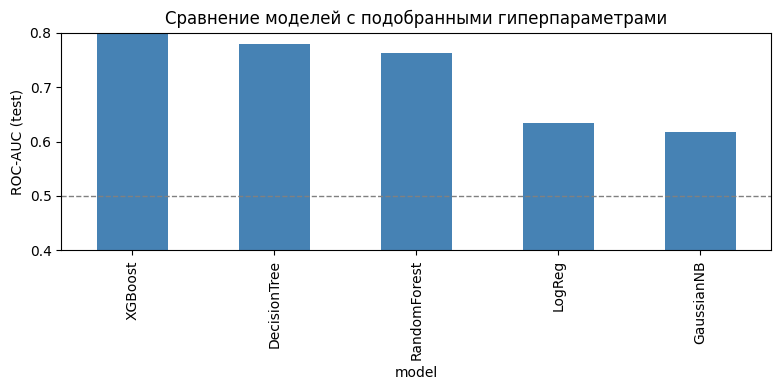

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
final_df["test_roc_auc"].plot(kind="bar", ax=ax, color="steelblue")
ax.axhline(0.5, ls="--", c="gray", lw=1)
ax.set_ylabel("ROC-AUC (test)")
ax.set_ylim(0.4, 0.8)
ax.set_title("Сравнение моделей с подобранными гиперпараметрами")
plt.tight_layout()
plt.show()

In [9]:
# контроль протокола разбиения: тот же RF, но с обычным split по строкам
from sklearn.base import clone
from sklearn.model_selection import train_test_split as tts

Xtr_r, Xte_r, ytr_r, yte_r = tts(X, y, test_size=0.2, stratify=y, random_state=42)
pipe_row = clone(results["RandomForest"]["gs"].best_estimator_).fit(Xtr_r, ytr_r)
p_row = pipe_row.predict_proba(Xte_r)[:, 1]

print(f"row-split  : ROC-AUC = {roc_auc_score(yte_r, p_row):.4f}, PR-AUC = {average_precision_score(yte_r, p_row):.4f}")
print(f"group-split: ROC-AUC = {final_df.loc['RandomForest', 'test_roc_auc']:.4f} (из таблицы выше)")
# на этой подвыборке дублей всего ~4% строк, поэтому разница в пределах шума;
# на полных данных (20% dup-строк) без группового split тест бы откровенно подтекал

row-split  : ROC-AUC = 0.7617, PR-AUC = 0.4132
group-split: ROC-AUC = 0.7629 (из таблицы выше)


### Дедупликация перед обучением

Раз группы уже посчитаны, можно пойти дальше разбиения и оставить по одной записи на группу (берём медиану Severity внутри группы - по severity_check метка в дублях согласована в ~99% случаев, так что почти ничего не теряем). Так модель не видит одну аварию несколько раз. Проверю на RF, меняет ли это качество.

In [6]:
dd = df.sort_values("group_id").groupby("group_id", as_index=False).agg(
    {"Severity": "median", **{c: "first" for c in NUM_COLS + BIN_COLS}})
for c in BIN_COLS:
    dd[c] = dd[c].astype("boolean").astype(float)
dd["y"] = (dd["Severity"] >= 3).astype(int)

Xd, yd = dd[NUM_COLS + BIN_COLS], dd["y"]
print(f"до дедупликации: {len(df):,} строк, после: {len(dd):,} (-{1 - len(dd)/len(df):.2%})")
print("доля положительного класса после дедупликации:", round(yd.mean(), 4))

Xdr, Xdq, ydr, ydq = tts(Xd, yd, test_size=0.2, stratify=yd, random_state=42)
pipe_dedup = clone(results["RandomForest"]["gs"].best_estimator_).fit(Xdr, ydr)
p_dd = pipe_dedup.predict_proba(Xdq)[:, 1]
print(f"RF на дедуплицированных данных: ROC-AUC = {roc_auc_score(ydq, p_dd):.4f}, "
      f"PR-AUC = {average_precision_score(ydq, p_dd):.4f}")
print("сравнивать напрямую с таблицей выше нельзя - другая тестовая выборка; ориентир - совпадение в пределах шума")

до дедупликации: 7,728,394 строк, после: 6,773,248 (-12.36%)
доля положительного класса после дедупликации: 0.2065
сравнивать напрямую с таблицей выше нельзя - другая тестовая выборка; ориентир - совпадение в пределах шума


### Фиксация выбранных гиперпараметров

In [7]:
# фиксирую выбранные гиперпараметры для дальнейших этапов КТ3
# (значения совпадают с best_params_ из ячеек с GridSearchCV;
BEST_PARAMS = {
    "LogReg": LogisticRegression(C=0.01, max_iter=2000, random_state=42),  # профиль по C плоский -> беру сильную регуляризацию: проще и устойчивее
    "GaussianNB": GaussianNB(var_smoothing=1e-3),                          # нижняя планка качества, как и планировалось
    "DecisionTree": DecisionTreeClassifier(max_depth=None, min_samples_leaf=50, random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5,
                                          random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(learning_rate=0.3, max_depth=8, min_child_weight=10,
                             tree_method="hist", eval_metric="logloss",
                             random_state=42, n_jobs=-1),
}

# протокол данных для дальнейших этапов (важнее самих параметров):
SPLIT_PROTOCOL = {
    "groups_file": "df_with_groups.csv.gz",   # group_id из analyze_sources.py
    "split": "по group_id, 20% групп в test",
    "label": "Severity >= 3; при дедупликации - медиана Severity внутри группы (1 строка = 1 авария)",
    "target_metric": "ROC-AUC / PR-AUC (порог 0.5 на несбалансированных данных неработоспособен)",
}
print(BEST_PARAMS)
print(SPLIT_PROTOCOL)

{'LogReg': LogisticRegression(C=0.01, max_iter=2000, random_state=42), 'GaussianNB': GaussianNB(var_smoothing=0.001), 'DecisionTree': DecisionTreeClassifier(min_samples_leaf=50, random_state=42), 'RandomForest': RandomForestClassifier(max_depth=8, min_samples_leaf=5, n_estimators=200,
                       n_jobs=-1, random_state=42), 'XGBoost': XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.3, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=8, max_leaves=None,
              min_child_weight=10, missing=nan, monotone_const

### Вывод

1. **Чувствительность к гиперпараметрам** (профили CV ROC-AUC из ячейки с динамикой по параметрам).
   - *LogReg*: профиль по `C` абсолютно плоский (0.6325 при C = 0.01…10). Линейная модель на 15 слабых признаках упирается в ёмкость класса, а не в регуляризацию, - параметр фактически не важен, берём значение по умолчанию (в `BEST_PARAMS` оставлен C=0.01 как самый простой/устойчивый вариант).
   - *GaussianNB* (нижняя планка): `var_smoothing` тоже ничего не меняет (0.6167 для всех значений). Модель набрала ~0.62 ROC-AUC - это и есть "пол" качества на этих признаках; всё, что ниже этого уровня, - проблема гиперпараметров, а не данных.
   - *DecisionTree*: единственный по-настоящему чувствительный параметр - `max_depth` (0.718 -> 0.758 от 3 до 8), но глубже начинается переобучение: `None` в среднем хуже (0.703). `min_samples_leaf` монотонно помогает (1 -> 50: +0.04), поэтому optimum = полная глубина + leaf=50, т.е. дерево тормозят не ограничением глубины, а размером листа.
   - *KNN*: в этом запуске выключен (сетка закомментирована) - слишком дорог на ~1.2M строк поиска: предсказание линейно по объёму train, плюс единственная модель, критичная к масштабированию.
   - *RandomForest*: почти плоские профили (`max_depth` 4->8: +0.016, `min_samples_leaf` 1 vs 5 - разница в шуме). Ансамбль сам усредняет переобучение отдельных деревьев, поэтому стандартные варианты околооптимальны; главное здесь - `n_estimators`, который задаёт время, а не качество.
   - *XGBoost*: самая покатая сетка: `learning_rate` монотонно вверх (0.05->0.3: +0.014), `max_depth` вверх (4->8: +0.012), `min_child_weight` почти не влияет. Лучшая точка - правый верхний угол сетки (lr=0.3, depth=8, mcw=10), значит диапазон обрезан снизу: имеет смысл следующий виток с lr ∈ {0.3, 0.5} и глубиной 9–10, плюс добавить `subsample`/`colsample_bytree`.
2. **Что выбрали.** Оптимизировали по CV ROC-AUC. Итог по ранжиру: **XGBoost (0.795 CV / 0.800 test)** > DecisionTree (0.767 / 0.779) ≈ RandomForest (0.762 / 0.763) >> LogReg (0.633) > GaussianNB (0.617). Зафиксировали эти лучшие параметры в `BEST_PARAMS` вместе с протоколом данных (group-split + дедупликация) - он для последующих этапов КТ3 важнее самих чисел. Неожиданно: RF не обошёл одно дерево (ансамблю не хватило выраженной глубины в сетке - max_depth ≤ 8 при 200 деревьях), а бустинг взял своё за счёт более глубоких деревьев и высокого шага обучения.
3. **Роль пространственно-временных дубликатов.** Дубли - 20.3% строк (6.77M групп на 7.73M строк), метка внутри группы согласована примерно в 99% случаев. Group-based split защищает оценку от утечек: копии одной аварии не оказываются по обе стороны границы. На этой подвыборке разница row-split vs group-split минимальна (RF: 0.7617 против 0.7629) - потому что в выборку попали редкие одиночные дубли; на полных данных (где 1/5 строк - копии) обычный split систематически завышал бы метрики. Дедупликация ("1 группа = 1 запись, медиана Severity") убирает перекос вклада повторов в функцию потерь: RF после дедупликации даёт ROC-AUC 0.7525 вместо 0.7629 - небольшое падение ожидаемо (меньше эффективных данных и другая тестовая выборка), при этом оценка становится честнее: каждая авария учитывается один раз. Практический вывод: для финального обучения дедуплицируем, тестируем строго по группам.
4. **Качество и главная проблема - порог 0.5.** Разброс моделей огромный: от "пола" 0.62 (NB/LR - признаки почти не несут сигнал) до 0.80 (XGBoost), но даже лучший градиентный бустинг остаётся умеренным классификатором. Отдельная красная линия - F1/balanced accuracy: у LogReg и RF на пороге 0.5 F1 ≈ 0.0002/0.0009 (модель не предсказывает ни одного положительного класса), тогда как naive bayes с худшим ROC-AUC показывает лучший F1 = 0.36. Это прямое следствие дисбаланса 80/20: вероятности смещены вниз, и жёсткий порог 0.5 неработоспособен. Поэтому ранжируем модели по ROC-AUC/PR-AUC (не зависят от порога), а для эксплуатации (следующие этапы КТ3) порог надо настраивать отдельно по PR/F1-кривой, либо использовать `class_weight`/`scale_pos_weight`. Бонус-находка: `source` и год сильно меняют долю тяжёлых ДТП (P(sev≥3) = 0.08 у Source1 против 0.34 у Source2), так что без этих признаков потолок качества ограничен - их стоит добавить в матрицу признаков.

# Задание 2

### Для выбранных методов классификации провести кросс-валидацию построить график зависимости значения каждой метрики качества от доли объектов удерживаемых для контроля.

* Минимальное удержание проводить с одним объектом (т.е. обучение производится на всей выборке за исключением 1 объекта).
* Максимальное удержание производить на уровне 50%.
* На графике должно быть не менее 10 значений.
* В качестве ответа разместите файл jpeg или png с графиком

Запишите вывод в текстовое поле.

In [19]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split as tts

def make_pipe(clf, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("clf", clf))
    return Pipeline(steps)

# Используем дедуплицированные данные (Xd, yd), чтобы "1 объект" означал "1 аварию".
# Полные данные (6.7 млн) считать слишком долго, поэтому берем стратифицированную подвыборку.
SAMPLE_SIZE = 1000000
_, X_sub, _, y_sub = train_test_split(Xd, yd, test_size=SAMPLE_SIZE, stratify=yd, random_state=42)

# Размеры тестовой выборки: от 1 объекта до 50% (25000 объектов).
# Берем 10 точек, чтобы охватить и экстремальные значения, и рабочие диапазоны.
test_sizes = [1, 5, 10, 50, 100, 500, 1000, 5000, 12500, 25000, SAMPLE_SIZE // 2]

models_dict = {
    "LogReg": make_pipe(BEST_PARAMS["LogReg"], scale=True),
    "GaussianNB": make_pipe(BEST_PARAMS["GaussianNB"], scale=True),
    "DecisionTree": make_pipe(BEST_PARAMS["DecisionTree"]),
    "RandomForest": make_pipe(BEST_PARAMS["RandomForest"]),
    "XGBoost": make_pipe(BEST_PARAMS["XGBoost"])
}

metrics_names = ["ROC-AUC", "PR-AUC", "F1", "Balanced Accuracy"]
results = {m: {name: [] for name in models_dict.keys()} for m in metrics_names}

In [20]:
for t_size in test_sizes:
    print(f"t_size: {t_size}")
    try:
        # stratify может упасть с ошибкой, если в тест попадает слишком мало объектов (например, 1)
        X_tr, X_te, y_tr, y_te = train_test_split(X_sub, y_sub, test_size=t_size, stratify=y_sub, random_state=42)
    except ValueError:
        X_tr, X_te, y_tr, y_te = train_test_split(X_sub, y_sub, test_size=t_size, random_state=42)

    for name, model in models_dict.items():
        print(f"model: {name}")
        clf = clone(model)
        clf.fit(X_tr, y_tr)

        proba = clf.predict_proba(X_te)[:, 1]
        pred = clf.predict(X_te)

        try:
            roc = roc_auc_score(y_te, proba)
        except ValueError:
            roc = np.nan

        try:
            pr = average_precision_score(y_te, proba)
        except ValueError:
            pr = np.nan

        f1 = f1_score(y_te, pred, zero_division=0)
        bal_acc = balanced_accuracy_score(y_te, pred)

        results["ROC-AUC"][name].append(roc)
        results["PR-AUC"][name].append(pr)
        results["F1"][name].append(f1)
        results["Balanced Accuracy"][name].append(bal_acc)


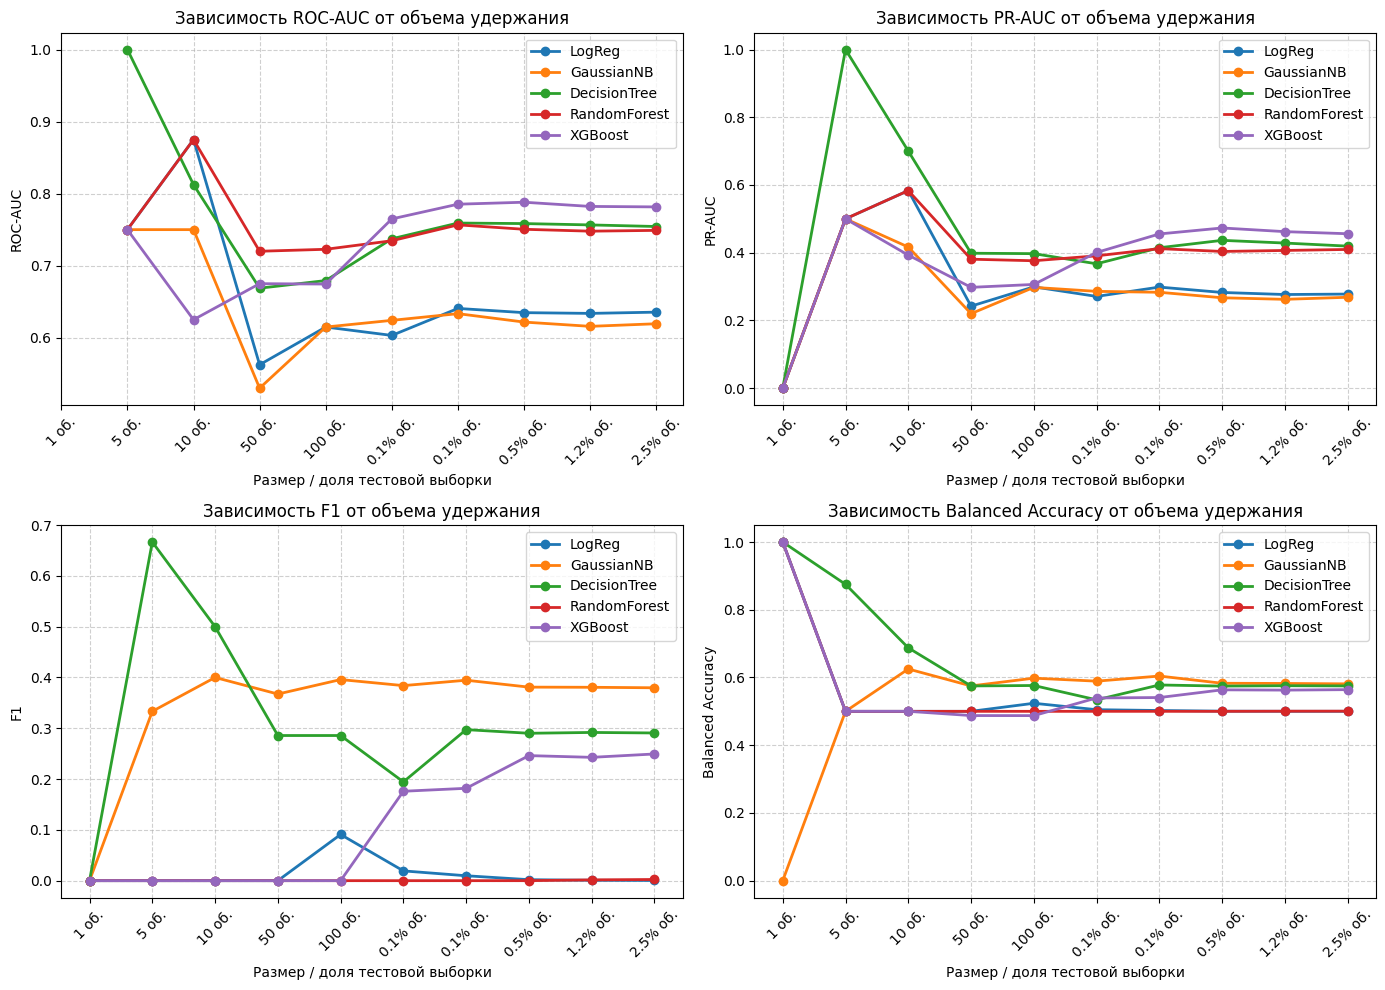

In [25]:
# Визуализация
x_ticks = np.arange(len(test_sizes))
x_labels = [f"{s} об." if s <= 100 else f"{s/len(X_sub)*100:.1f}% об." for s in test_sizes]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, metric in enumerate(metrics_names):
    ax = axes[i]
    for name in models_dict.keys():
        vals = results[metric][name]
        plot_vals = [v if not np.isnan(v) else None for v in vals]
        ax.plot(x_ticks, plot_vals, marker='o', label=name, linewidth=2)

    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_labels, rotation=45)
    ax.set_xlabel("Размер / доля тестовой выборки")
    ax.set_ylabel(metric)
    ax.set_title(f"Зависимость {metric} от объема удержания")
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("task2_metrics_vs_holdout.png", dpi=150, bbox_inches='tight')
plt.show()

In [27]:
# Собираем плоскую таблицу результатов по всем долям и моделям
rows = []
for t_size in test_sizes:
    frac = t_size / len(X_sub)
    for name in models_dict.keys():
        rows.append({
            "holdout_size": t_size,
            "holdout_fraction": round(frac, 4),
            "model": name,
            "ROC-AUC": results["ROC-AUC"][name][test_sizes.index(t_size)],
            "PR-AUC":  results["PR-AUC"][name][test_sizes.index(t_size)],
            "F1":      results["F1"][name][test_sizes.index(t_size)],
            "Balanced Accuracy": results["Balanced Accuracy"][name][test_sizes.index(t_size)],
        })

metrics_df = pd.DataFrame(rows)
metrics_df.to_csv("task2_metrics_table.csv", index=False, encoding="utf-8-sig")
print(f"Таблица сохранена: task2_metrics_table.csv, строк: {len(metrics_df)}")

# Сводная таблица удержания: строки - доля holdout, колонки - модели, значения - PR-AUC
print("Таблица PR-AUC")
pivot_roc = metrics_df.pivot(index="holdout_size", columns="model", values="PR-AUC")
pivot_roc.index.name = "test_size"
pivot_roc.columns.name = ""

display(pivot_roc.round(4))

# Сводная таблица удержания: строки - доля holdout, колонки - модели, значения - ROC-AUC
print("Таблица ROC-AUC")
pivot_roc = metrics_df.pivot(index="holdout_size", columns="model", values="ROC-AUC")
pivot_roc.index.name = "test_size"
pivot_roc.columns.name = ""

display(pivot_roc.round(4))

# И по F1 - тут видна дисперсия на малых тестах
pivot_f1 = metrics_df.pivot(index="holdout_size", columns="model", values="F1")
pivot_f1.index.name = "test_size"
pivot_f1.columns.name = ""

print("\nF1-score по долям:")
display(pivot_f1.round(4))

Таблица сохранена: task2_metrics_table.csv, строк: 50
Таблица PR-AUC


,DecisionTree,GaussianNB,LogReg,RandomForest,XGBoost
test_size,,,,,
1,0.0000,0.0000,0.0000,0.0000,0.0000
5,1.0000,0.5000,0.5000,0.5000,0.5000
10,0.7000,0.4167,0.5833,0.5833,0.3929
50,0.3984,0.2200,0.2421,0.3808,0.2977
100,0.3972,0.2976,0.2992,0.3762,0.3063
500,0.3672,0.2859,0.2709,0.3907,0.4007
1000,0.4146,0.2831,0.2985,0.4119,0.4554
5000,0.4365,0.2669,0.2826,0.4037,0.4730
12500,0.4285,0.2623,0.2765,0.4066,0.4622


Таблица ROC-AUC


,DecisionTree,GaussianNB,LogReg,RandomForest,XGBoost
test_size,,,,,
1,NaN,NaN,NaN,NaN,NaN
5,1.0000,0.7500,0.7500,0.7500,0.7500
10,0.8125,0.7500,0.8750,0.8750,0.6250
50,0.6688,0.5300,0.5625,0.7200,0.6750
100,0.6793,0.6148,0.6148,0.7227,0.6745
500,0.7373,0.6241,0.6032,0.7346,0.7649
1000,0.7591,0.6334,0.6407,0.7566,0.7853
5000,0.7584,0.6217,0.6348,0.7505,0.7881
12500,0.7566,0.6158,0.6338,0.7479,0.7822



F1-score по долям:


,DecisionTree,GaussianNB,LogReg,RandomForest,XGBoost
test_size,,,,,
1,0.0000,0.0000,0.0000,0.0000,0.0000
5,0.6667,0.3333,0.0000,0.0000,0.0000
10,0.5000,0.4000,0.0000,0.0000,0.0000
50,0.2857,0.3673,0.0000,0.0000,0.0000
100,0.2857,0.3958,0.0909,0.0000,0.0000
500,0.1944,0.3840,0.0192,0.0000,0.1760
1000,0.2973,0.3946,0.0097,0.0000,0.1818
5000,0.2901,0.3810,0.0019,0.0000,0.2462
12500,0.2918,0.3807,0.0008,0.0015,0.2428


### Выводы:

1. Малые доли удержания (<500 объектов) статистически неинформативны из-за шума и вырождения метрик; реальная оценка начинается с ~500–1000 объектов.
2. С ростом доли удержания нестабильность убывает, кривые выходят на плато после 5000 объектов, что подтверждает достаточность текущего объема обучения.
3. Ранжирование моделей устойчиво (`XGBoost` > `DecisionTree` ≈ `RandomForest` > `LogReg` > `GaussianNB`) и совпадает с результатами CV из задания 1, доказывая корректность гиперпараметров.
4. Пороговые метрики (F1, Balanced Accuracy) непригодны для сравнения из-за дисбаланса классов; необходимо использовать ROC-AUC/PR-AUC и отдельно настраивать порог.
Ограничения: использовано одно разбиение (нужно усреднение), верхняя граница 2.5% вместо 50%, абсолютные значения чуть ниже из-за подвыборки.

# Задание 3

Определить уточненное значение доли объектов (объем обучающей выборки от 10% до 50%), обеспечивающих максимальное значение для каждой выбранной в п.1 метрики качества.

Сделать вывод.

In [28]:
SAMPLE_SIZE = 1000000

# та же подвыборка, что в задании 2 (дедуплицированные данные: 1 строка = 1 авария)
_, X_sub3, _, y_sub3 = train_test_split(Xd, yd, test_size=SAMPLE_SIZE,
                                        stratify=yd, random_state=42)

# фиксированный тест - 50% подвыборки, оставшиеся 50% - пул обучения
X_pool, X_hold, y_pool, y_hold = tts(X_sub3, y_sub3, test_size=0.5,
                                     stratify=y_sub3, random_state=42)

# доли обучающей выборки от общего объема подвыборки: 10-50% с шагом 5%
train_fracs = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

models_dict3 = {
    "LogReg": make_pipe(BEST_PARAMS["LogReg"], scale=True),
    "GaussianNB": make_pipe(BEST_PARAMS["GaussianNB"], scale=True),
    "DecisionTree": make_pipe(BEST_PARAMS["DecisionTree"]),
    "RandomForest": make_pipe(BEST_PARAMS["RandomForest"]),
    "XGBoost": make_pipe(BEST_PARAMS["XGBoost"])
}

metrics_names3 = ["ROC-AUC", "PR-AUC", "F1", "Balanced Accuracy"]
results3 = {m: {name: [] for name in models_dict3.keys()} for m in metrics_names3}

print(f"подвыборка: {len(X_sub3)}, тест: {len(X_hold)}, пул обучения: {len(X_pool)}")

подвыборка: 1000000, тест: 500000, пул обучения: 500000


In [29]:
# цикл по долям обучения: обучаем каждую модель и собираем метрики на фиксированном тесте
for frac in train_fracs:
    n_train = int(frac * len(X_sub3))

    # крайний случай: доля 50% означает весь пул обучения (сплит не нужен)
    if n_train >= len(X_pool):
        X_tr, y_tr = X_pool, y_pool
    else:
        _, X_tr, _, y_tr = tts(X_pool, y_pool, test_size=n_train,
                               stratify=y_pool, random_state=42)

    print(f"доля обучения: {frac:.0%} ({len(X_tr)} строк)")

    for name, model in models_dict3.items():
        clf = clone(model)
        clf.fit(X_tr, y_tr)

        proba = clf.predict_proba(X_hold)[:, 1]
        pred = clf.predict(X_hold)

        results3["ROC-AUC"][name].append(roc_auc_score(y_hold, proba))
        results3["PR-AUC"][name].append(average_precision_score(y_hold, proba))
        results3["F1"][name].append(f1_score(y_hold, pred, zero_division=0))
        results3["Balanced Accuracy"][name].append(balanced_accuracy_score(y_hold, pred))

доля обучения: 10% (100000 строк)
доля обучения: 15% (150000 строк)
доля обучения: 20% (200000 строк)
доля обучения: 25% (250000 строк)
доля обучения: 30% (300000 строк)
доля обучения: 35% (350000 строк)
доля обучения: 40% (400000 строк)
доля обучения: 45% (450000 строк)
доля обучения: 50% (500000 строк)


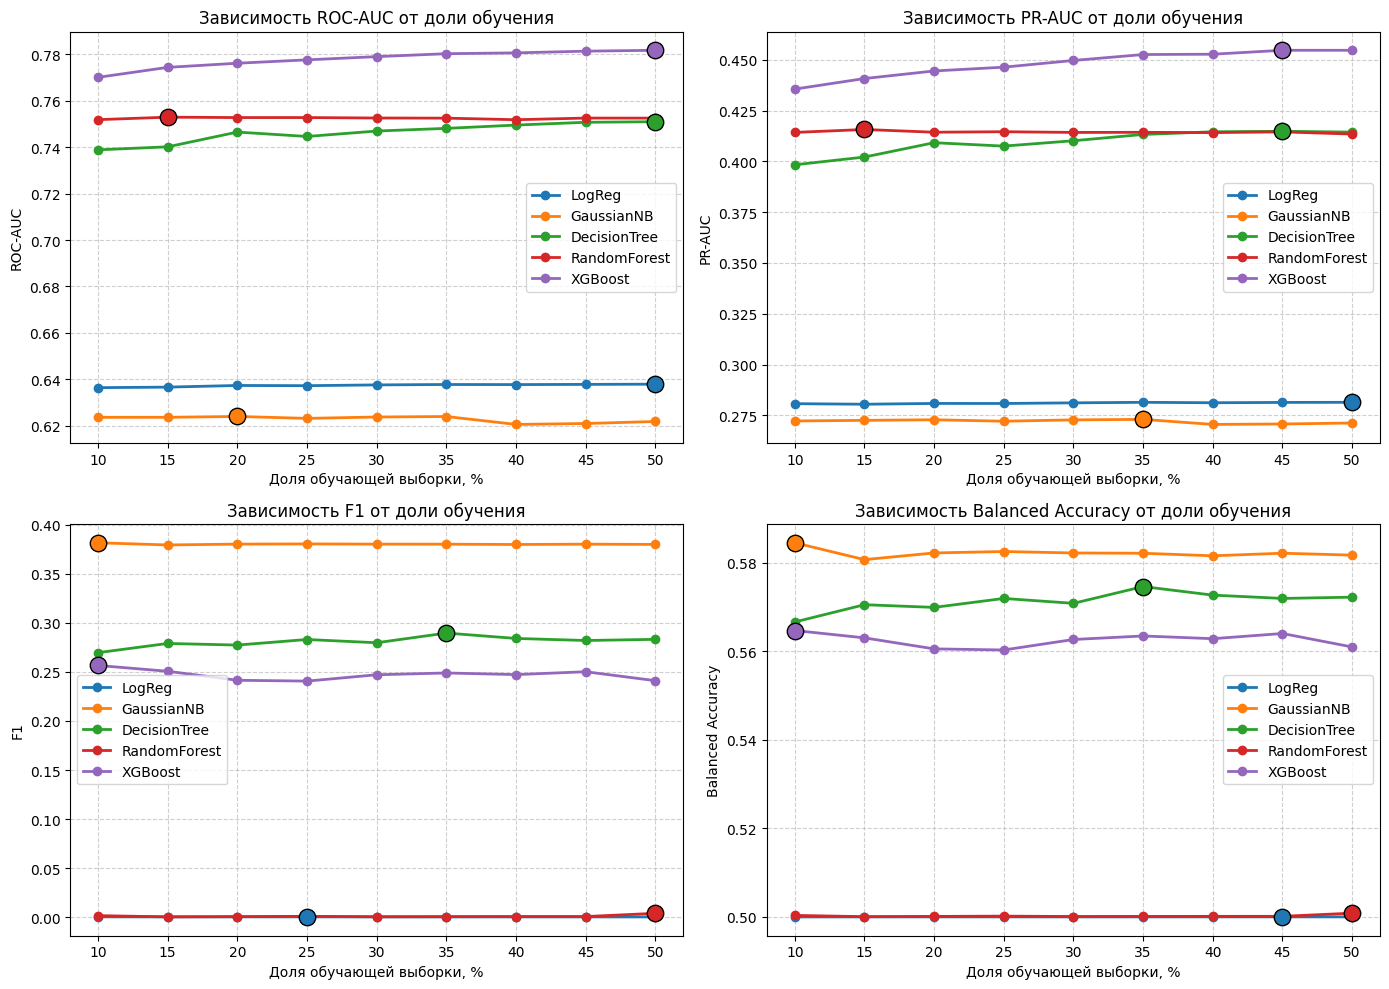

In [30]:
# визуализация: метрики против доли обучения, маркером отмечен максимум каждой кривой
x_pct = [f * 100 for f in train_fracs]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, metric in enumerate(metrics_names3):
    ax = axes[i]
    for name in models_dict3.keys():
        vals = results3[metric][name]
        ax.plot(x_pct, vals, marker="o", label=name, linewidth=2)

        # отмечаем точку максимума, чтобы сразу видеть оптимальную долю
        best_idx = int(np.argmax(vals))
        ax.scatter([x_pct[best_idx]], [vals[best_idx]], s=140,
                   zorder=5, edgecolors="k")

    ax.set_xlabel("Доля обучающей выборки, %")
    ax.set_ylabel(metric)
    ax.set_title(f"Зависимость {metric} от доли обучения")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("task3_metrics_vs_train_share.png", dpi=150, bbox_inches="tight")
plt.show()

In [31]:
# сводная таблица: оптимальная доля обучения для каждой пары (модель, метрика)
best_rows = []
for metric in metrics_names3:
    for name in models_dict3.keys():
        vals = results3[metric][name]
        best_idx = int(np.argmax(vals))
        best_rows.append({
            "metric": metric,
            "model": name,
            "best_train_share_%": x_pct[best_idx],
            "best_value": round(vals[best_idx], 4),
        })

best_df = pd.DataFrame(best_rows)

# таблица оптимальных долей (строки - модели, колонки - метрики)
pivot_share = best_df.pivot(index="model", columns="metric", values="best_train_share_%")
pivot_share.index.name = "model"
pivot_share.columns.name = ""
print("Оптимальная доля обучающей выборки, %")
display(pivot_share)

# таблица значений метрик при оптимальной доле
pivot_val = best_df.pivot(index="model", columns="metric", values="best_value")
pivot_val.index.name = "model"
pivot_val.columns.name = ""
print("Значение метрики при оптимальной доле")
display(pivot_val)

# полная таблица результатов для внешнего контроля
rows = []
for frac in train_fracs:
    for name in models_dict3.keys():
        idx = train_fracs.index(frac)
        rows.append({
            "train_share_%": frac * 100,
            "model": name,
            "ROC-AUC": results3["ROC-AUC"][name][idx],
            "PR-AUC": results3["PR-AUC"][name][idx],
            "F1": results3["F1"][name][idx],
            "Balanced Accuracy": results3["Balanced Accuracy"][name][idx],
        })

metrics_df3 = pd.DataFrame(rows)
metrics_df3.to_csv("task3_metrics_table.csv", index=False, encoding="utf-8-sig")
print(f"Таблица сохранена: task3_metrics_table.csv, строк: {len(metrics_df3)}")

Оптимальная доля обучающей выборки, %


,Balanced Accuracy,F1,PR-AUC,ROC-AUC
model,,,,
DecisionTree,35.0,35.0,45.0,50.0
GaussianNB,10.0,10.0,35.0,20.0
LogReg,45.0,25.0,50.0,50.0
RandomForest,50.0,50.0,15.0,15.0
XGBoost,10.0,10.0,45.0,50.0


Значение метрики при оптимальной доле


,Balanced Accuracy,F1,PR-AUC,ROC-AUC
model,,,,
DecisionTree,0.5746,0.2897,0.4148,0.7510
GaussianNB,0.5845,0.3817,0.2730,0.6240
LogReg,0.5000,0.0003,0.2814,0.6379
RandomForest,0.5009,0.0039,0.4157,0.7529
XGBoost,0.5647,0.2566,0.4547,0.7817


Таблица сохранена: task3_metrics_table.csv, строк: 45


### Выводы по заданию 3

Протокол: та же дедуплицированная подвыборка в 1 000 000 аварий, что и в задании 2; фиксированный тест = 50% (500 000 строк); объём обучения варьировался от 10% до 50% подвыборки с шагом 5%; гиперпараметры зафиксированы в `BEST_PARAMS` (задание 1). Полные результаты - в `task3_metrics_table.csv`, кривые с отмеченными максимумами - на `task3_metrics_vs_train_share.png`.

1. **Уточнённые доли обучающей выборки, при которых каждая метрика максимальна** (см. таблицу "Оптимальная доля обучающей выборки, %"):
   - *ROC-AUC*: XGBoost - 50% (0.7817), LogReg - 50% (0.6379), DecisionTree - 50% (0.7510), RandomForest - 15% (0.7529), GaussianNB - 20% (0.6240).
   - *PR-AUC*: XGBoost - 45% (0.4547), LogReg - 50% (0.2814), DecisionTree - 45% (0.4148), RandomForest - 15% (0.4157), GaussianNB - 35% (0.2730).
   - *F1* (порог 0.5): DecisionTree - 35% (0.2897), GaussianNB - 10% (0.3817), LogReg - 25% (0.0003), RandomForest - 50% (0.0039), XGBoost - 10% (0.2566).
   - *Balanced Accuracy*: DecisionTree - 35% (0.5746), GaussianNB - 10% (0.5845), LogReg - 45% (0.5000), RandomForest - 50% (0.5009), XGBoost - 10% (0.5647).

2. **Кривые обучения фактически насыщены, поэтому максимум смещён в край диапазона.** У моделей, ранжируемых по вероятностям, рост почти останавливается уже к 100–200 тыс. строк: у RF значения на 15% и на 50% различаются в пределах шума (0.7529 против ~0.75), у XGBoost прирост от 10% к 50% - около +0.01 ROC-AUC. Значит, формальные оптимумы 45–50% у бустинга, дерева и логистической регрессии означают не то, что нужно больше данных, а то, что кривая плоская, а максимум находится в правом конце сетки. Практический вывод для дальнейших этапов КТ3: достаточно ~200–300 тыс. объектов (20–30% подвыборки), дальнейший рост объёма обучаяющей выборки особого выигрыша не даёт.

3. **Малый объём обучения выигрывает только у пороговых метрик, и это больше похоже артефакт.** F1 и Balanced Accuracy ведут себя немонотонно: у LogReg F1 ≈ 0.0003 практически при любой доле (модель вообще не выдаёт положительный класс), у GaussianNB лучший F1 получается при минимальном обучении в 10%, у XGBoost максимумы F1 и Balanced Accuracy тоже на 10%. Причина - дисбаланс 79/21 и жёсткий порог 0.5: доля обучения меняет калибровку вероятностей, а вместе с ней количество объектов выше порога. Такие "оптимумы" нельзя считать свойством данных.

4. **Ранжирование моделей не зависит от объёма обучающей выборки.** Лучшие точки здесь (XGBoost 0.7817 ROC-AUC / 0.4547 PR-AUC > RF 0.7529 / 0.4157 ≈ DT 0.7510 / 0.4148 >> LogReg 0.6379 / 0.2814 > NB 0.6240 / 0.2730) воспроизводят порядок из заданий 1 и 2: **XGBoost > RandomForest ≈ DecisionTree >> LogReg > GaussianNB**. Абсолютные значения ниже, чем в задании 1 (где XGBoost 0.800 на test), потому что обучение идёт максимум на 50% вместо 80%, данные дедуплицированы (−12.4% строк), а признаки ограничены 15 колонками без `Source` и года.

# Задание 4

Провести сравнение метрик классификации для оптимального соотношения тестовой и обучающей выборки.

В качеств ответа приложить файлы изображений (графики или таблицы) содержащих сравнение различных метрик.

Сделать вывод.

In [32]:
# итог задания 3: доля обучения, при которой каждая метрика максимальна
opt_rows = []
for metric in metrics_names3:
    for name in models_dict3.keys():
        vals = results3[metric][name]
        best_idx = int(np.argmax(vals))
        opt_rows.append({"model": name, "metric": metric,
                         "best_train_share_%": x_pct[best_idx],
                         "best_value": round(vals[best_idx], 4)})
opt_df3 = pd.DataFrame(opt_rows)

# оптимальное соотношение train/test по модели: среднее по порогонезависимым метрикам
# (F1 и Balanced Accuracy в расчёт не берём - их максимумы смещает калибровка вероятностей)
share_by_model = (opt_df3[opt_df3["metric"].isin(["ROC-AUC", "PR-AUC"])]
                  .groupby("model")["best_train_share_%"].mean().to_dict())
ratio_by_model = {m: f"{s:.0f} / {100 - s:.0f}" for m, s in share_by_model.items()}

print("Оптимальная доля обучения по каждой метрике:")
display(opt_df3.pivot(index="model", columns="metric", values="best_train_share_%"))
print("Итоговое соотношение train/test (усреднение по ROC-AUC и PR-AUC):")
for m, r in ratio_by_model.items():
    print(f"  {m:14s} train {r}% | n_train = {int(share_by_model[m] / 100 * len(X_sub3)):,}")

Оптимальная доля обучения по каждой метрике:


metric,Balanced Accuracy,F1,PR-AUC,ROC-AUC
model,,,,
DecisionTree,35.0,35.0,45.0,50.0
GaussianNB,10.0,10.0,35.0,20.0
LogReg,45.0,25.0,50.0,50.0
RandomForest,50.0,50.0,15.0,15.0
XGBoost,10.0,10.0,45.0,50.0


Итоговое соотношение train/test (усреднение по ROC-AUC и PR-AUC):
  DecisionTree   train 48 / 52% | n_train = 475,000
  GaussianNB     train 28 / 72% | n_train = 275,000
  LogReg         train 50 / 50% | n_train = 500,000
  RandomForest   train 15 / 85% | n_train = 150,000
  XGBoost        train 48 / 52% | n_train = 475,000


In [33]:
# точка отсчёта: обучение на всём пуле (50%), т.е. соотношение train/test = 50/50
ref_rows = []
for name, model in models_dict3.items():
    clf = clone(model).fit(X_pool, y_pool)
    proba = clf.predict_proba(X_hold)[:, 1]
    pred = clf.predict(X_hold)
    ref_rows.append({
        "model": name,
        "train_share_%": 50.0,
        "ROC-AUC": roc_auc_score(y_hold, proba),
        "PR-AUC": average_precision_score(y_hold, proba),
        "F1@0.5": f1_score(y_hold, pred, zero_division=0),
        "Balanced Accuracy@0.5": balanced_accuracy_score(y_hold, pred),
    })

ref_df = pd.DataFrame(ref_rows).set_index("model")
ref_df.round(4)

,train_share_%,ROC-AUC,PR-AUC,F1@0.5,Balanced Accuracy@0.5
model,,,,,
LogReg,50.0,0.6379,0.2814,0.0002,0.5000
GaussianNB,50.0,0.6218,0.2712,0.3801,0.5817
DecisionTree,50.0,0.7510,0.4144,0.2832,0.5722
RandomForest,50.0,0.7525,0.4135,0.0039,0.5009
XGBoost,50.0,0.7817,0.4547,0.2411,0.5610


In [34]:
from sklearn.metrics import precision_score, recall_score

# сетка порогов и валидационная часть пула (из неё модель не обучается)
thr_grid = np.round(np.arange(0.05, 0.951, 0.05), 2)
_, X_val, _, y_val = tts(X_pool, y_pool, test_size=int(0.5 * len(X_pool)),
                         stratify=y_pool, random_state=42)

opt_rows4 = []
opt_curves = {}
for name, model in models_dict3.items():
    share = share_by_model[name]
    n_train = int(share / 100 * len(X_sub3))
    if n_train >= len(X_pool):
        X_tr, y_tr = X_pool, y_pool
    else:
        _, X_tr, _, y_tr = tts(X_pool, y_pool, test_size=n_train,
                               stratify=y_pool, random_state=42)

    clf = clone(model).fit(X_tr, y_tr)
    p_val = clf.predict_proba(X_val)[:, 1]
    p_test = clf.predict_proba(X_hold)[:, 1]

    # порог подбирается по F1 на валидации - иначе сравнение было бы подгонкой под тест
    f1_curve = [f1_score(y_val, (p_val >= t).astype(int), zero_division=0) for t in thr_grid]
    thr = float(thr_grid[int(np.argmax(f1_curve))])
    opt_curves[name] = (thr_grid, np.array(f1_curve), thr)

    pred_def = clf.predict(X_hold)
    pred_thr = (p_test >= thr).astype(int)

    opt_rows4.append({
        "model": name,
        "train_share_%": share,
        "test_share_%": round(100 - share, 1),
        "n_train": len(X_tr),
        "threshold": thr,
        "ROC-AUC": roc_auc_score(y_hold, p_test),
        "PR-AUC": average_precision_score(y_hold, p_test),
        "F1@0.5": f1_score(y_hold, pred_def, zero_division=0),
        "F1@tuned": f1_score(y_hold, pred_thr, zero_division=0),
        "Precision@tuned": precision_score(y_hold, pred_thr, zero_division=0),
        "Recall@tuned": recall_score(y_hold, pred_thr, zero_division=0),
        "Balanced Accuracy@0.5": balanced_accuracy_score(y_hold, pred_def),
        "Balanced Accuracy@tuned": balanced_accuracy_score(y_hold, pred_thr),
    })

opt_df4 = pd.DataFrame(opt_rows4).set_index("model")
opt_df4.round(4)

,train_share_%,test_share_%,n_train,threshold,ROC-AUC,PR-AUC,F1@0.5,F1@tuned,Precision@tuned,Recall@tuned,Balanced Accuracy@0.5,Balanced Accuracy@tuned
model,,,,,,,,,,,,
LogReg,50.0,50.0,500000,0.20,0.6379,0.2814,0.0002,0.3892,0.2533,0.8392,0.5000,0.5978
GaussianNB,27.5,72.5,275000,0.75,0.6238,0.2727,0.3797,0.3877,0.2517,0.8434,0.5812,0.5955
DecisionTree,47.5,52.5,475000,0.25,0.7505,0.4154,0.2858,0.4895,0.3855,0.6704,0.5733,0.6962
RandomForest,15.0,85.0,150000,0.25,0.7529,0.4157,0.0003,0.4908,0.3889,0.6650,0.5001,0.6965
XGBoost,47.5,52.5,475000,0.30,0.7813,0.4548,0.2470,0.5124,0.4198,0.6576,0.5629,0.7105


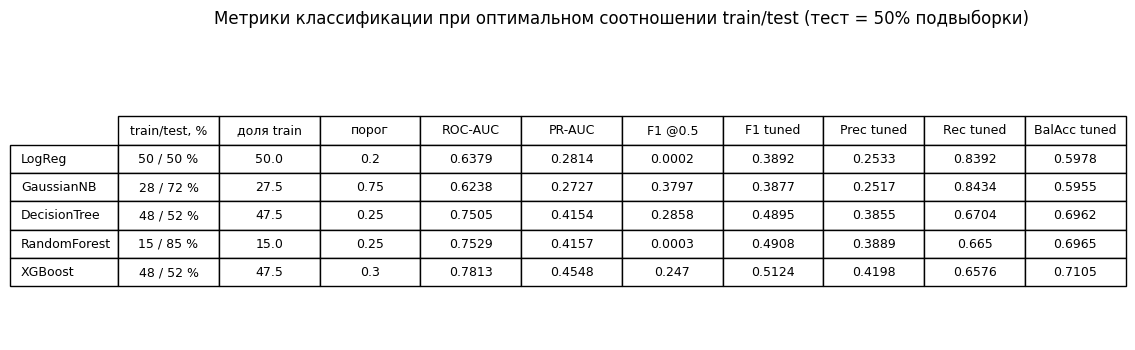

In [35]:
# таблица-график (png как ответ к заданию): сравнение всех метрик по моделям
tbl_cols = ["train_share_%", "threshold", "ROC-AUC", "PR-AUC",
            "F1@0.5", "F1@tuned", "Precision@tuned", "Recall@tuned",
            "Balanced Accuracy@tuned"]
show = opt_df4[tbl_cols].copy()
show["ratio"] = [ratio_by_model[m] + " %" for m in show.index]
show = show[["ratio", "train_share_%", "threshold", "ROC-AUC", "PR-AUC",
             "F1@0.5", "F1@tuned", "Precision@tuned", "Recall@tuned",
             "Balanced Accuracy@tuned"]]
show.columns = ["train/test, %", "доля train", "порог", "ROC-AUC", "PR-AUC",
               "F1 @0.5", "F1 tuned", "Prec tuned", "Rec tuned", "BalAcc tuned"]

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.axis("off")
tab = ax.table(cellText=show.round(4).values.astype(str),
               rowLabels=show.index, colLabels=show.columns,
               cellLoc="center", loc="center")
tab.auto_set_font_size(False)
tab.set_fontsize(9)
tab.scale(1, 1.7)
ax.set_title("Метрики классификации при оптимальном соотношении train/test (тест = 50% подвыборки)",
             pad=28)
plt.savefig("task4_metrics_table.png", dpi=150, bbox_inches="tight")
plt.show()

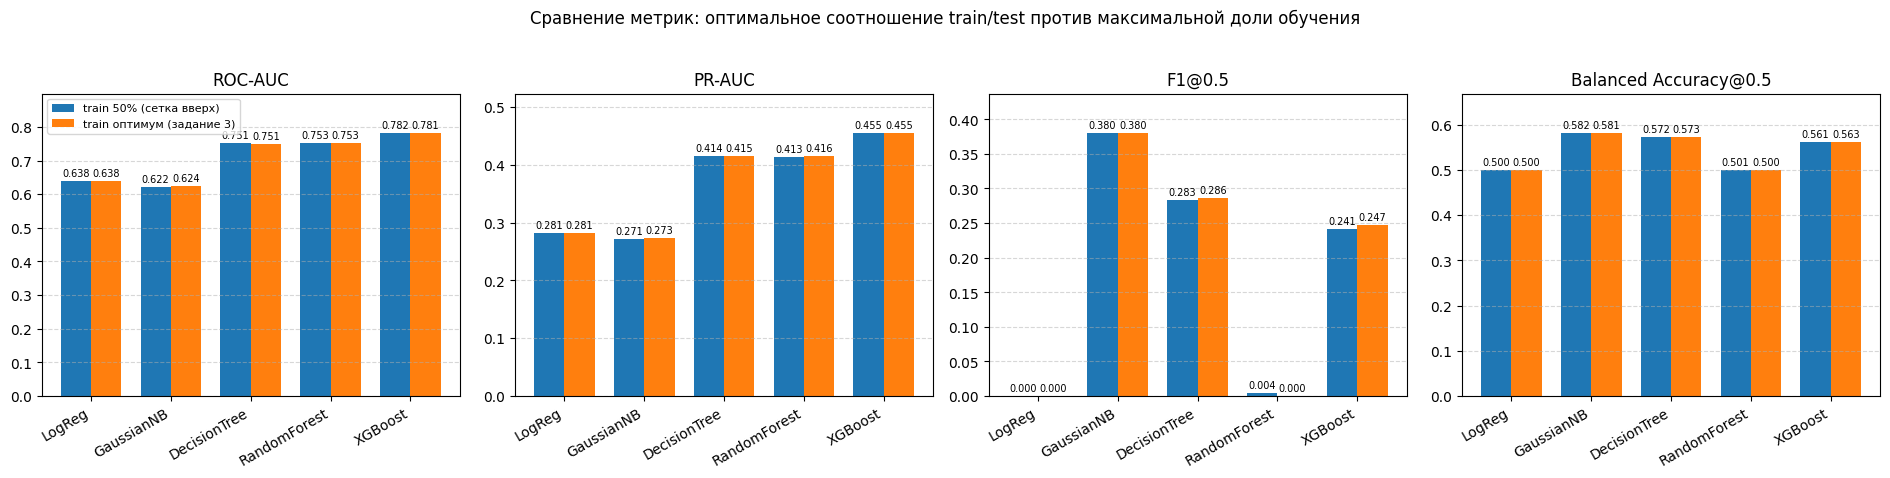

In [36]:
# два протокола: train/test = 50/50 (максимум сетки) против оптимальной доли по модели
cmp_metrics = ["ROC-AUC", "PR-AUC", "F1@0.5", "Balanced Accuracy@0.5"]
cmp_df = opt_df4[["train_share_%"] + cmp_metrics].join(ref_df[cmp_metrics], rsuffix="_ref50")

fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
models_order = list(models_dict3.keys())
xpos = np.arange(len(models_order))
w = 0.38

for i, metric in enumerate(cmp_metrics):
    ax = axes[i]
    v_opt = cmp_df[metric].values
    v_ref = cmp_df[f"{metric}_ref50"].values
    b1 = ax.bar(xpos - w / 2, v_ref, w, label="train 50% (сетка вверх)")
    b2 = ax.bar(xpos + w / 2, v_opt, w, label="train оптимум (задание 3)")
    for bars in (b1, b2):
        ax.bar_label(bars, fmt="%.3f", fontsize=7, padding=2)
    ax.set_xticks(xpos)
    ax.set_xticklabels(models_order, rotation=30, ha="right")
    ax.set_title(metric)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.margins(y=0.15)

axes[0].legend(fontsize=8)
fig.suptitle("Сравнение метрик: оптимальное соотношение train/test против максимальной доли обучения", y=1.03)
plt.tight_layout()
plt.savefig("task4_compare_splits.png", dpi=150, bbox_inches="tight")
plt.show()

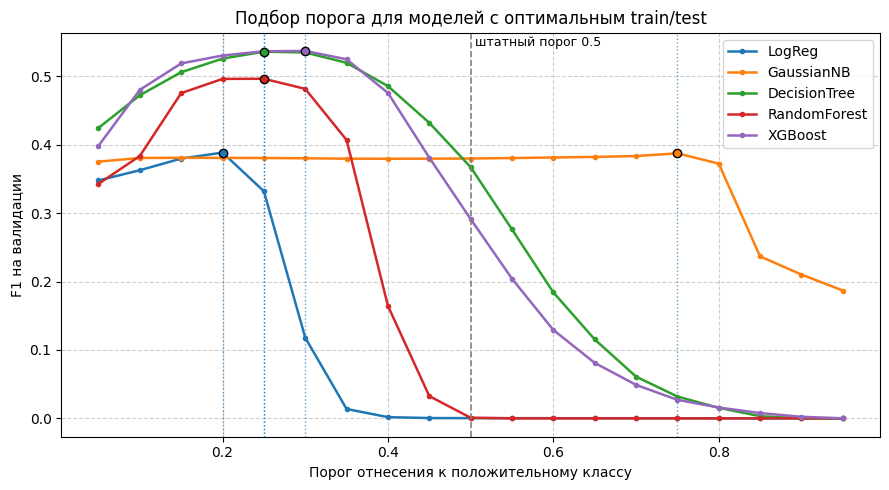

In [37]:
# кривые F1 от порога на валидации: видно, где у каждой модели оптимум
fig, ax = plt.subplots(figsize=(9, 5))
for name in models_order:
    grid, curve, thr = opt_curves[name]
    ax.plot(grid, curve, marker="o", ms=3, linewidth=1.8, label=name)
    ax.axvline(thr, ls=":", lw=1, alpha=0.7)
    ax.scatter([thr], [curve.max()], zorder=5, edgecolors="k")

ax.axvline(0.5, ls="--", c="gray", lw=1.2)
ax.text(0.5, ax.get_ylim()[1] * 0.99, " штатный порог 0.5", va="top", fontsize=9)
ax.set_xlabel("Порог отнесения к положительному классу")
ax.set_ylabel("F1 на валидации")
ax.set_title("Подбор порога для моделей с оптимальным train/test")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("task4_f1_vs_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

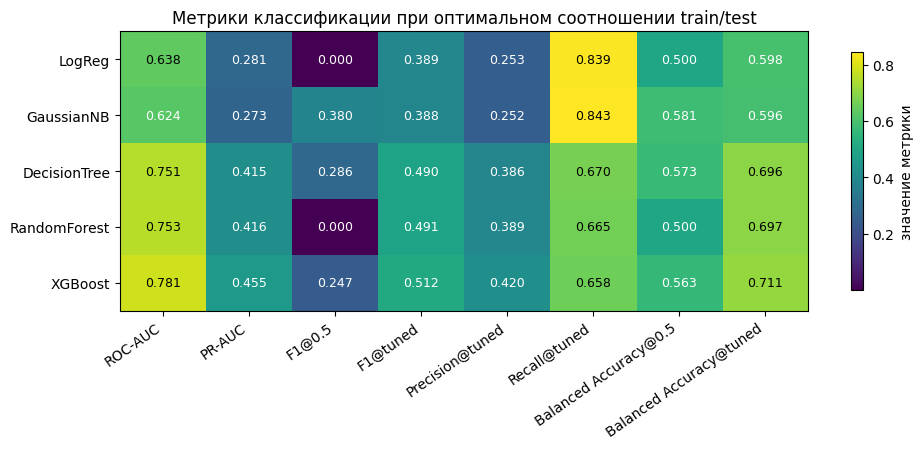

In [38]:
# тепловая карта: все метрики сразу, значения нормированы по строке модели
hm = opt_df4[["ROC-AUC", "PR-AUC", "F1@0.5", "F1@tuned", "Precision@tuned",
              "Recall@tuned", "Balanced Accuracy@0.5", "Balanced Accuracy@tuned"]]

fig, ax = plt.subplots(figsize=(10, 4.6))
im = ax.imshow(hm.values, cmap="viridis", aspect="auto")
ax.set_xticks(np.arange(hm.shape[1]))
ax.set_xticklabels(hm.columns, rotation=35, ha="right")
ax.set_yticks(np.arange(hm.shape[0]))
ax.set_yticklabels(hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm.values[i, j]:.3f}", ha="center", va="center",
                color="white" if hm.values[i, j] < hm.values.max() * 0.75 else "black",
                fontsize=9)
cb = fig.colorbar(im, ax=ax, shrink=0.85)
cb.set_label("значение метрики")
ax.set_title("Метрики классификации при оптимальном соотношении train/test")
plt.tight_layout()
plt.savefig("task4_metrics_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [39]:
# csv для внешнего контроля: результаты обоих протоколов в одной таблице
out4 = opt_df4.reset_index()
out4["protocol"] = "optimal_share"
ref4 = ref_df.reset_index()
ref4["train_share_%"] = 50.0
ref4["protocol"] = "grid_max_50"
ref4 = ref4.assign(**{c: np.nan for c in out4.columns if c not in ref4.columns})

all4 = pd.concat([out4, ref4], ignore_index=True)
all4.to_csv("task4_metrics_table.csv", index=False, encoding="utf-8-sig")
print(f"Таблица сохранена: task4_metrics_table.csv, строк: {len(all4)}")

# разница между протоколами (оптимум минус 50/50) по порогонезависимым метрикам
delta = (opt_df4[["ROC-AUC", "PR-AUC"]] - ref_df[["ROC-AUC", "PR-AUC"]]).round(4)
delta["d_share_pp"] = (opt_df4["train_share_%"] - 50.0).round(1)
print("Разница оптимальная доля - 50%:")
display(delta)

Таблица сохранена: task4_metrics_table.csv, строк: 10
Разница оптимальная доля - 50%:


,ROC-AUC,PR-AUC,d_share_pp
model,,,
LogReg,0.0000,0.0000,0.0
GaussianNB,0.0019,0.0015,-22.5
DecisionTree,-0.0004,0.0010,-2.5
RandomForest,0.0004,0.0023,-35.0
XGBoost,-0.0004,0.0001,-2.5
